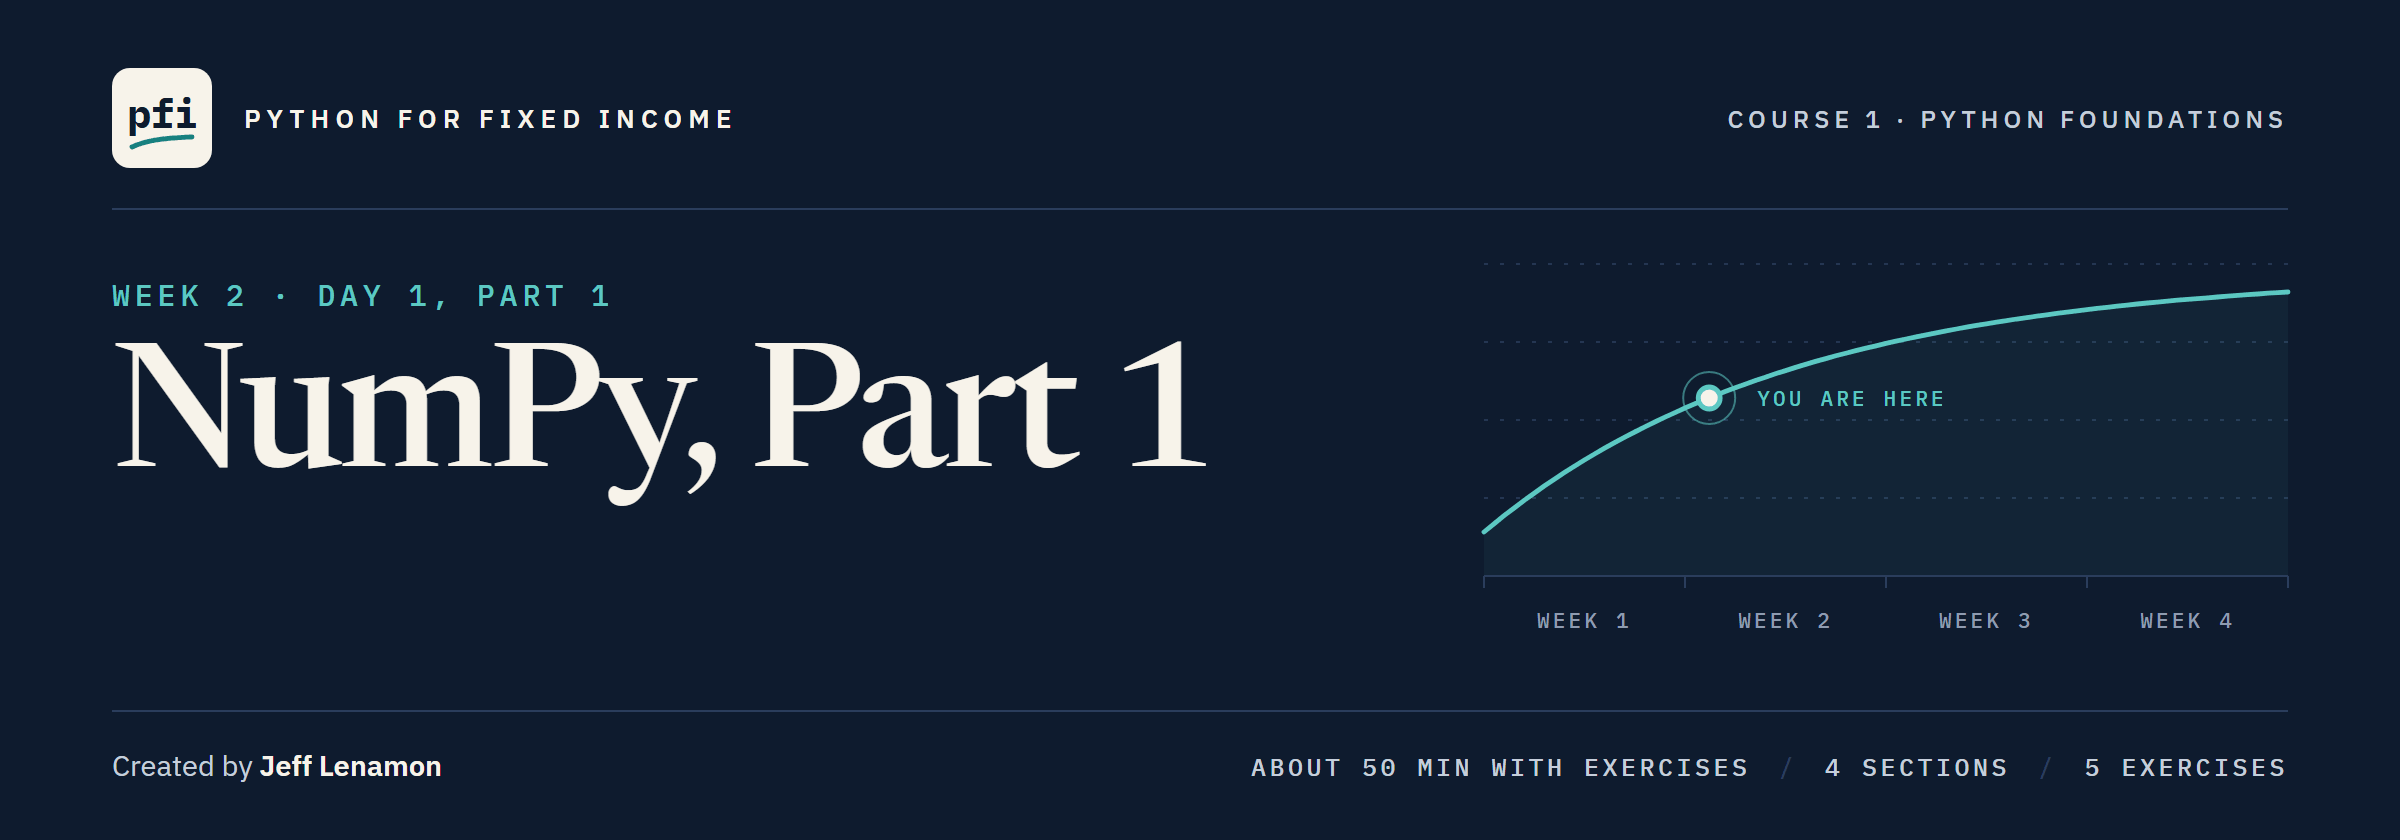

# NumPy, Part 1

Week 2, Day 1, Part 1. Doing arithmetic on a whole column of bonds in one step.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week2/day1/06_numpy.ipynb)

## The Desk Lead's Eighth Note

> Last week every column question took a loop. This week, one line each, on the four bonds of Days 1 to 4, so every answer checks against last week's: each position's cost and income, each bond's current yield, the top yielder, and the average coupon that matches our cash. Then make me a year of test yield moves, and tell me what QVNE returned this week.

**NumPy** is the library for this: its **array** holds a column and calculates on all of it at once.

**Start from week 1's lists.**

## Your Route Through Day 1, Part 1

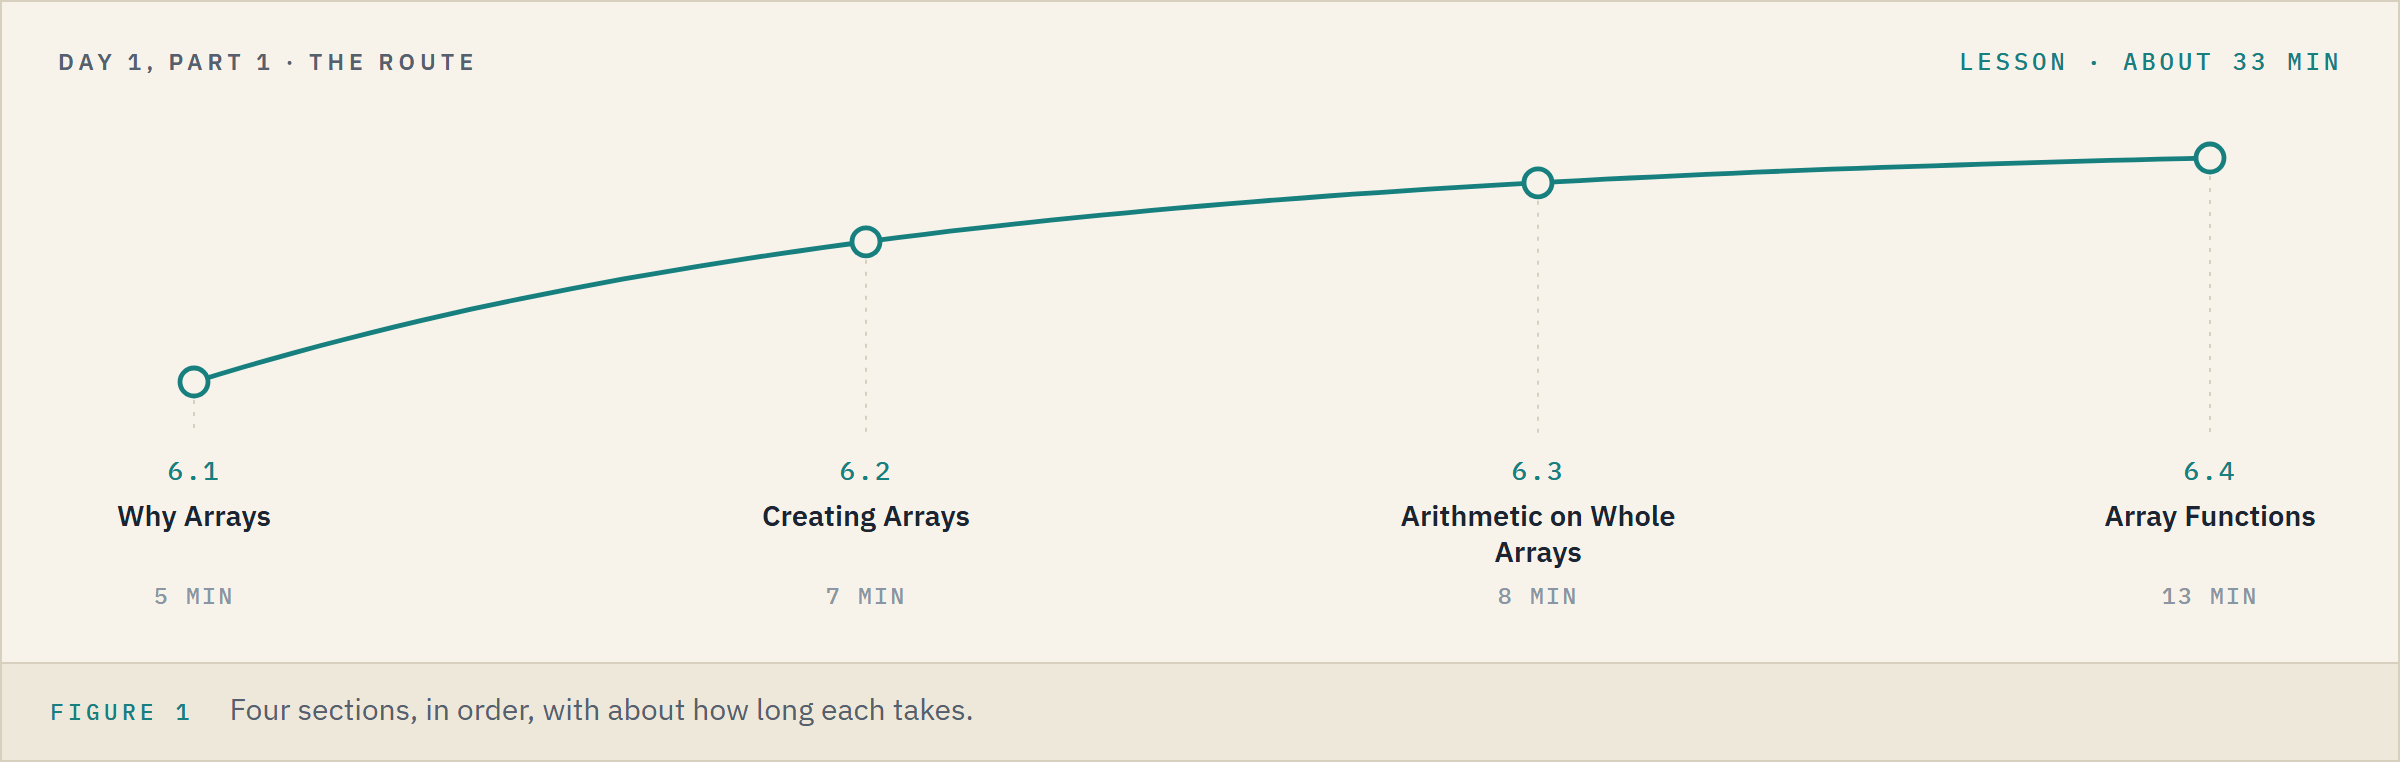

**Time.** About 33 minutes for the lesson, then about 15 for the five exercises.

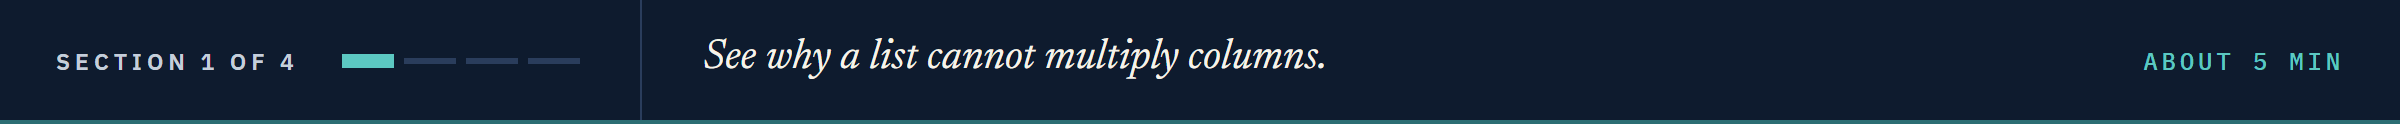

## 6.1 Why Arrays

### A List Cannot Multiply

Q. What did each position cost? Store week 1's lists, then multiply faces by prices, over 100.

Q. Double every price, then put a `+` between two lists of prices.

In [1]:
# week 1's lists, one per column, the bonds in the same order
ticker_list = ['QVNE', 'DNMR', 'PLWK', 'HLVF']
coupon_list = [5.25, 6.125, 4.75, 7.5]
price_list = [98.5, 103.25, 95.0, 101.0]
face_list = [1500000, 500000, 750000, 250000]

In [2]:
# face times price, list by list: this cell is meant to fail
face_list * price_list / 100

TypeError: can't multiply sequence by non-int of type 'list'

In [3]:
# times 2: double every price?
print(price_list * 2)
# QVNE and DNMR this morning and this afternoon, joined by +
morning = [98.5, 103.25]
afternoon = [98.75, 103.0]
print(morning + afternoon)

[98.5, 103.25, 95.0, 101.0, 98.5, 103.25, 95.0, 101.0]
[98.5, 103.25, 98.75, 103.0]


Day 3 met this message on text: a list is a sequence too.

**A list does no arithmetic: it stops with an error, or worse, answers wrong in silence.**

### The Week 1 Way

Q. Cost each position with week 1's Part 2 loop.

In [4]:
# start empty, then one position at a time, as in week 1's Part 2
cost_list = []
for face, price in zip(face_list, price_list):
    cost_list.append(face * price / 100)
print(cost_list)

[1477500.0, 516250.0, 712500.0, 252500.0]


**Four lines to say face times price over 100, and a new loop for every question.**

### One Line With NumPy

NumPy came with pandas when Day 0 installed it (pandas is built on it), so only the import is left.

Q. Import NumPy, make the faces and prices arrays, and cost every position in one line.

In [5]:
# import NumPy as np: the short name every NumPy user gives it, as pd for pandas
import numpy as np

# np.array() turns a list into an array
faces = np.array(face_list)
prices = np.array(price_list)
# one line for all four bonds
costs = faces * prices / 100
print(costs)

[1477500.  516250.  712500.  252500.]


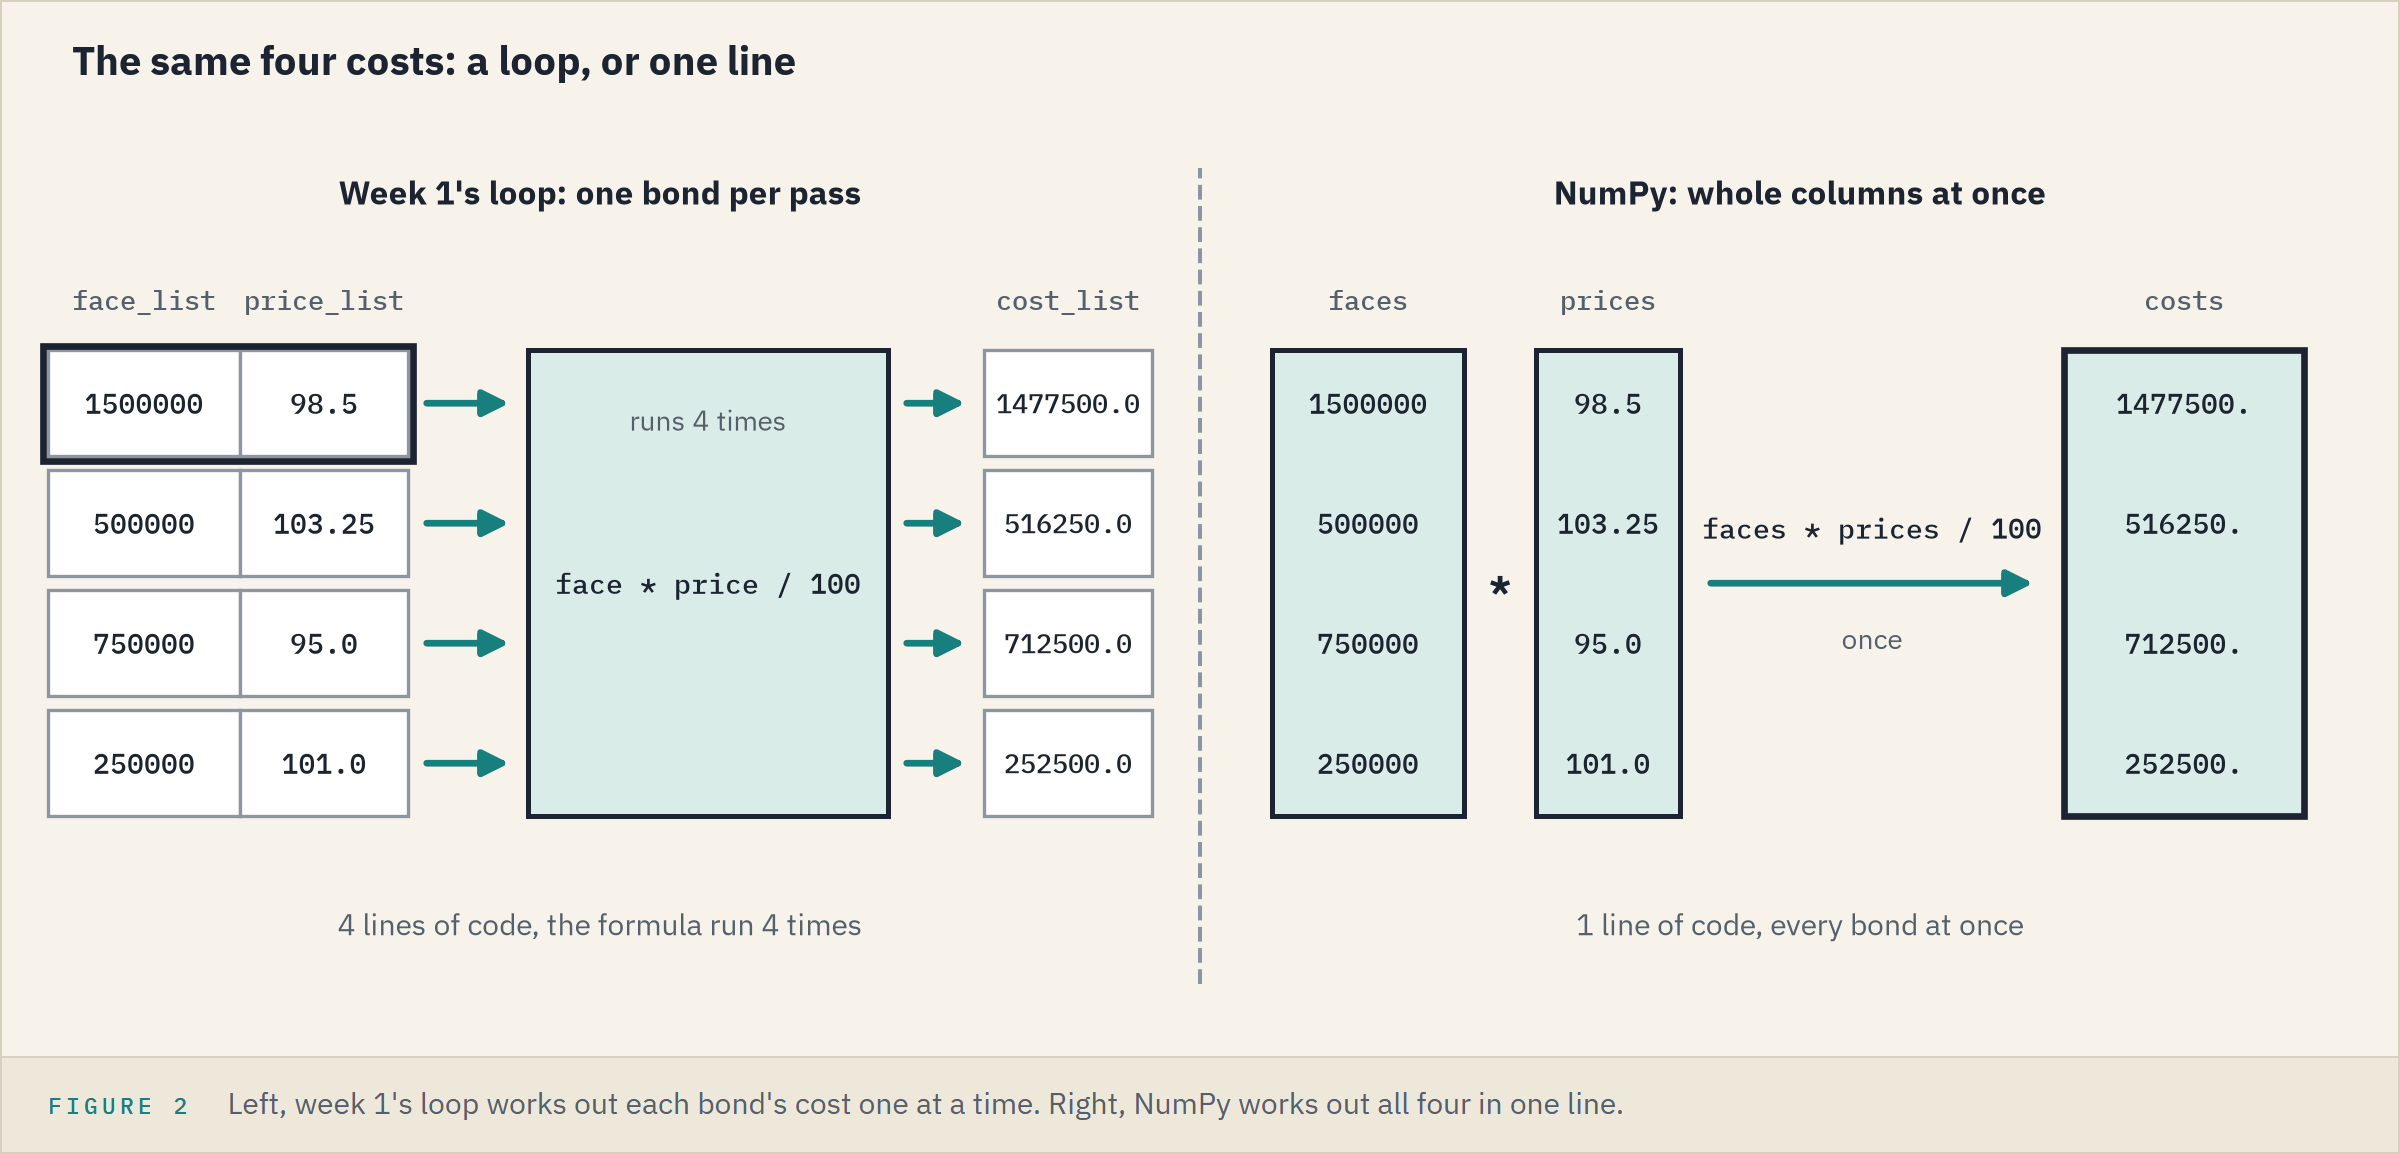

`516250.` is how an array prints 516250.0.

**Excel side by side.** With face in B and price in C, `=B2*C2/100` filled down gives the four costs.
In Microsoft 365 and Excel 2021, `=B2:B5*C2:C5/100` in one cell spills all four: the closer match.

**With arrays, `*` multiplies, value by value.**

> STORY: NumPy appeared in 2005, uniting two earlier array libraries; the first, Numeric, dates from the mid-1990s.
> Its developers write that it was part of the software behind the discovery of gravitational waves and the first image of a black hole.
> They list finance and economics among the fields that rely on it.
>
> Source: [Harris et al., "Array programming with NumPy", Nature 585, 357-362 (2020)](https://www.nature.com/articles/s41586-020-2649-2)

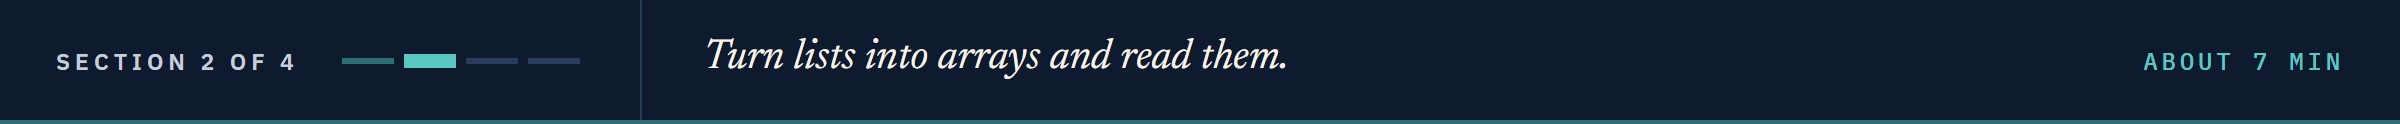

## 6.2 Creating Arrays

### What an Array Is

Q. What type is `prices`? Make arrays of the tickers and the coupons too.

In [6]:
# type(), from week 1's Part 1
print(type(prices))
# from a list's name, or from a list typed in place
tickers = np.array(ticker_list)
coupons = np.array([5.25, 6.125, 4.75, 7.5])
print(tickers)
print(coupons)

<class 'numpy.ndarray'>
['QVNE' 'DNMR' 'PLWK' 'HLVF']
[5.25  6.125 4.75  7.5  ]


`ndarray`: an n-dimensional array.
Spaces and no commas tell an array from a list.

**It looks like a list. Look inside.**

### One Type, One Shape

Q. What type of value does each array hold, and how big is `prices`?

In [7]:
# dtype is the type of every value inside: an attribute, so no brackets (Day 4)
print('coupons:', coupons.dtype)
print('faces:', faces.dtype)
print('tickers:', tickers.dtype)
# size counts the values, ndim the dimensions, shape the length along each
print('size:', prices.size, 'ndim:', prices.ndim, 'shape:', prices.shape)

coupons: float64
faces: int64
tickers: <U4
size: 4 ndim: 1 shape: (4,)


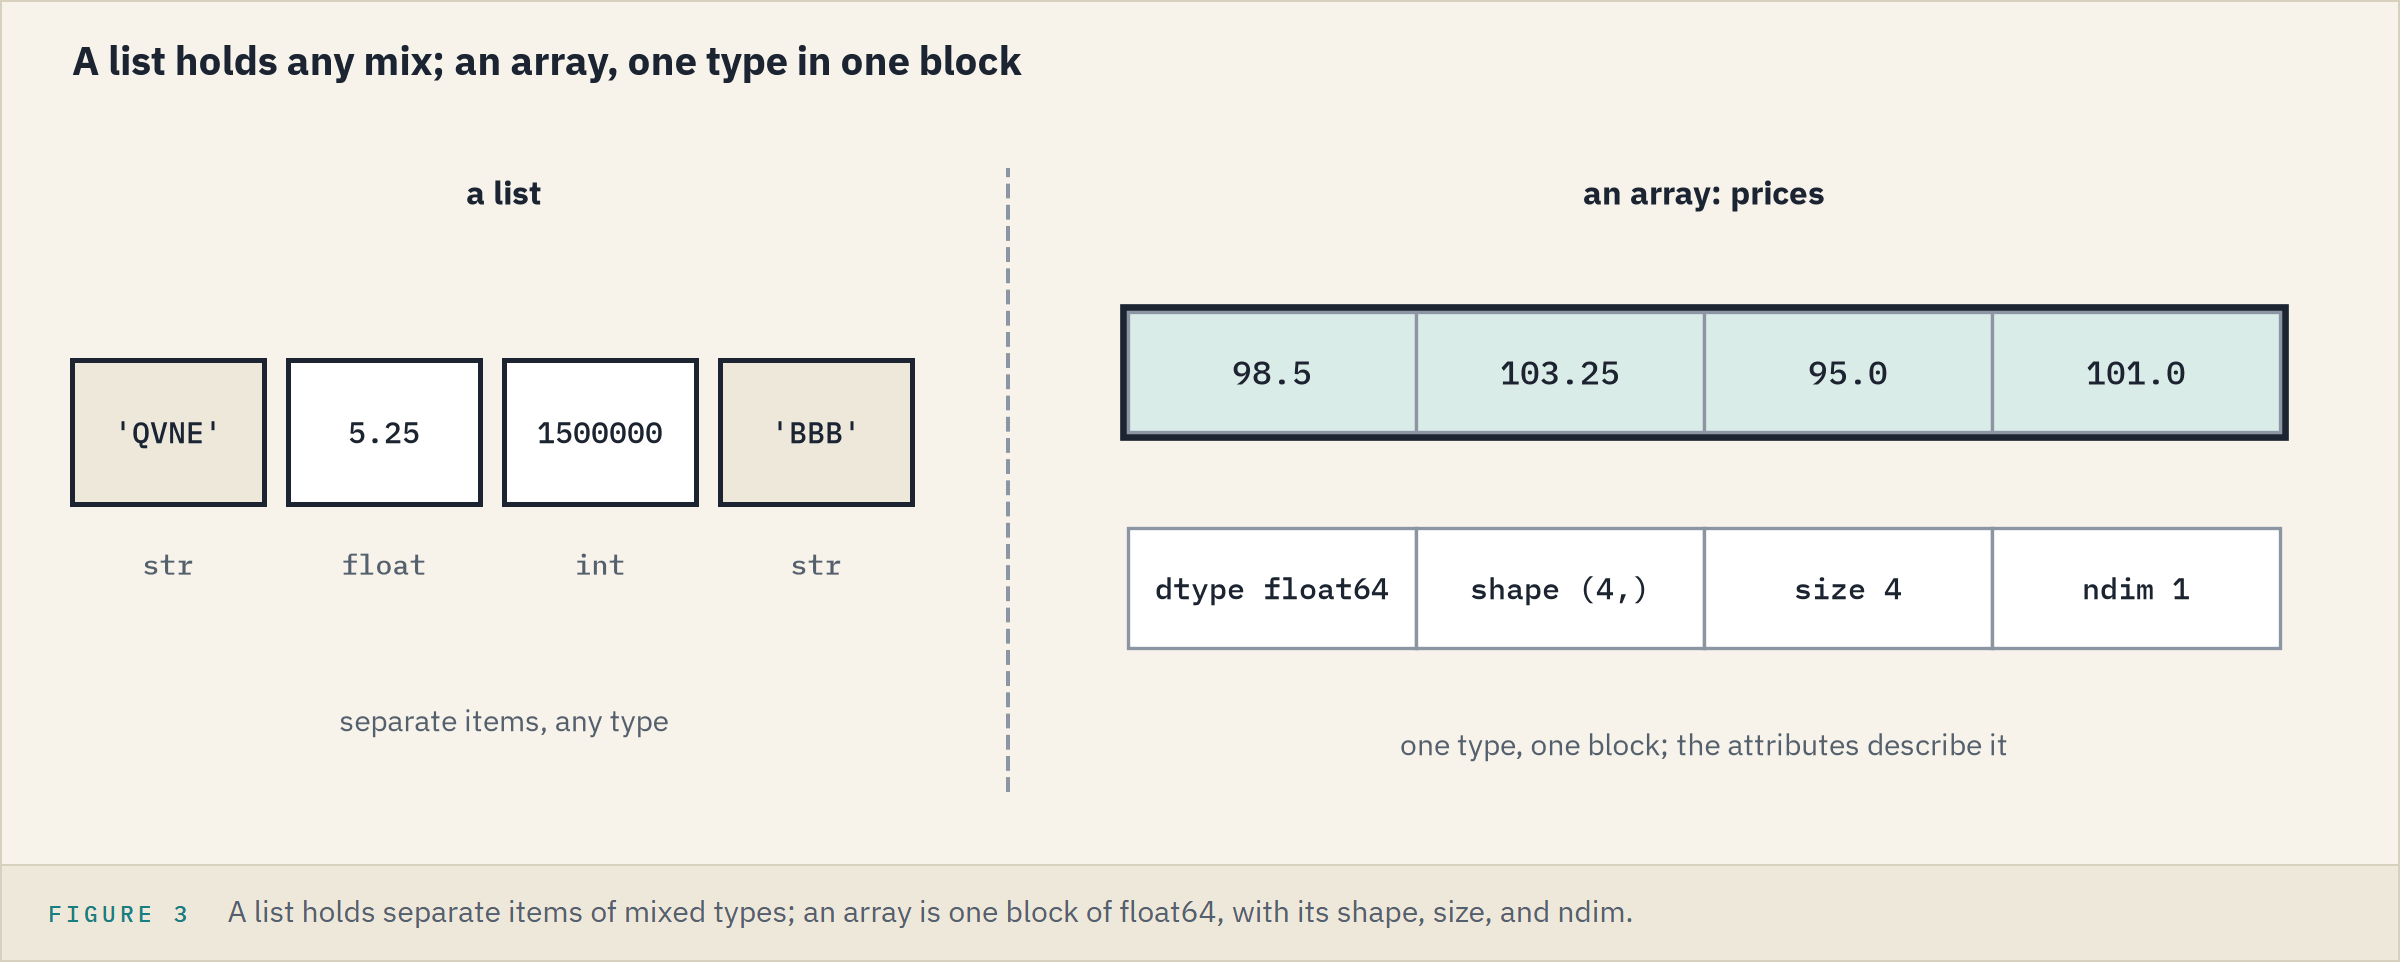

One type is part of what makes an array quick.

<table align="left">
<tr><th align="left">In the output</th><th align="left">It means</th></tr>
<tr><td align="left"><code>float64</code></td><td align="left">a decimal, 64 bits (8 bytes) a value: Day 5's decimals</td></tr>
<tr><td align="left"><code>int64</code></td><td align="left">a whole number, the same size</td></tr>
<tr><td align="left"><code>&lt;U4</code></td><td align="left">text: Unicode, up to 4 characters; ignore the <code>&lt;</code></td></tr>
<tr><td align="left"><code>(4,)</code></td><td align="left">a tuple (week 1's Part 1) of one item: the comma marks it a tuple. One dimension, four bonds</td></tr>
</table>
<br clear="left">

**Now mix two types in one list.**

### A Ticker and a Coupon in One Array

**Predict 1**

Q. The next cell puts a ticker and its coupon in one array. What happens?

A) An error.
B) The ticker stays text, the coupon a number.
C) Both become text.

In [8]:
# a ticker and its coupon in one list
mixed = np.array(['QVNE', 5.25])
print(mixed)
print(mixed.dtype)

['QVNE' '5.25']
<U32


C: the coupon is now the text '5.25', with no arithmetic possible.

**One array per column, as in a spreadsheet.**

### Runs of Numbers

Q. Build prices from 95 to 105, one point apart.

Q. QVNE pays a coupon every six months for 7 years. Build the payment times, 0.5 to 7.0 years, by step, then by count.

In [9]:
# np.arange(start, stop, step): like range() in week 1's Part 2, the stop left out
print(np.arange(95, 106, 1))
# unlike range(), np.arange() takes a decimal step
print(np.arange(0.5, 7.5, 0.5))
# np.linspace(start, stop, count): count values, both ends included
print(np.linspace(0.5, 7, 14))

[ 95  96  97  98  99 100 101 102 103 104 105]
[0.5 1.  1.5 2.  2.5 3.  3.5 4.  4.5 5.  5.5 6.  6.5 7. ]
[0.5 1.  1.5 2.  2.5 3.  3.5 4.  4.5 5.  5.5 6.  6.5 7. ]


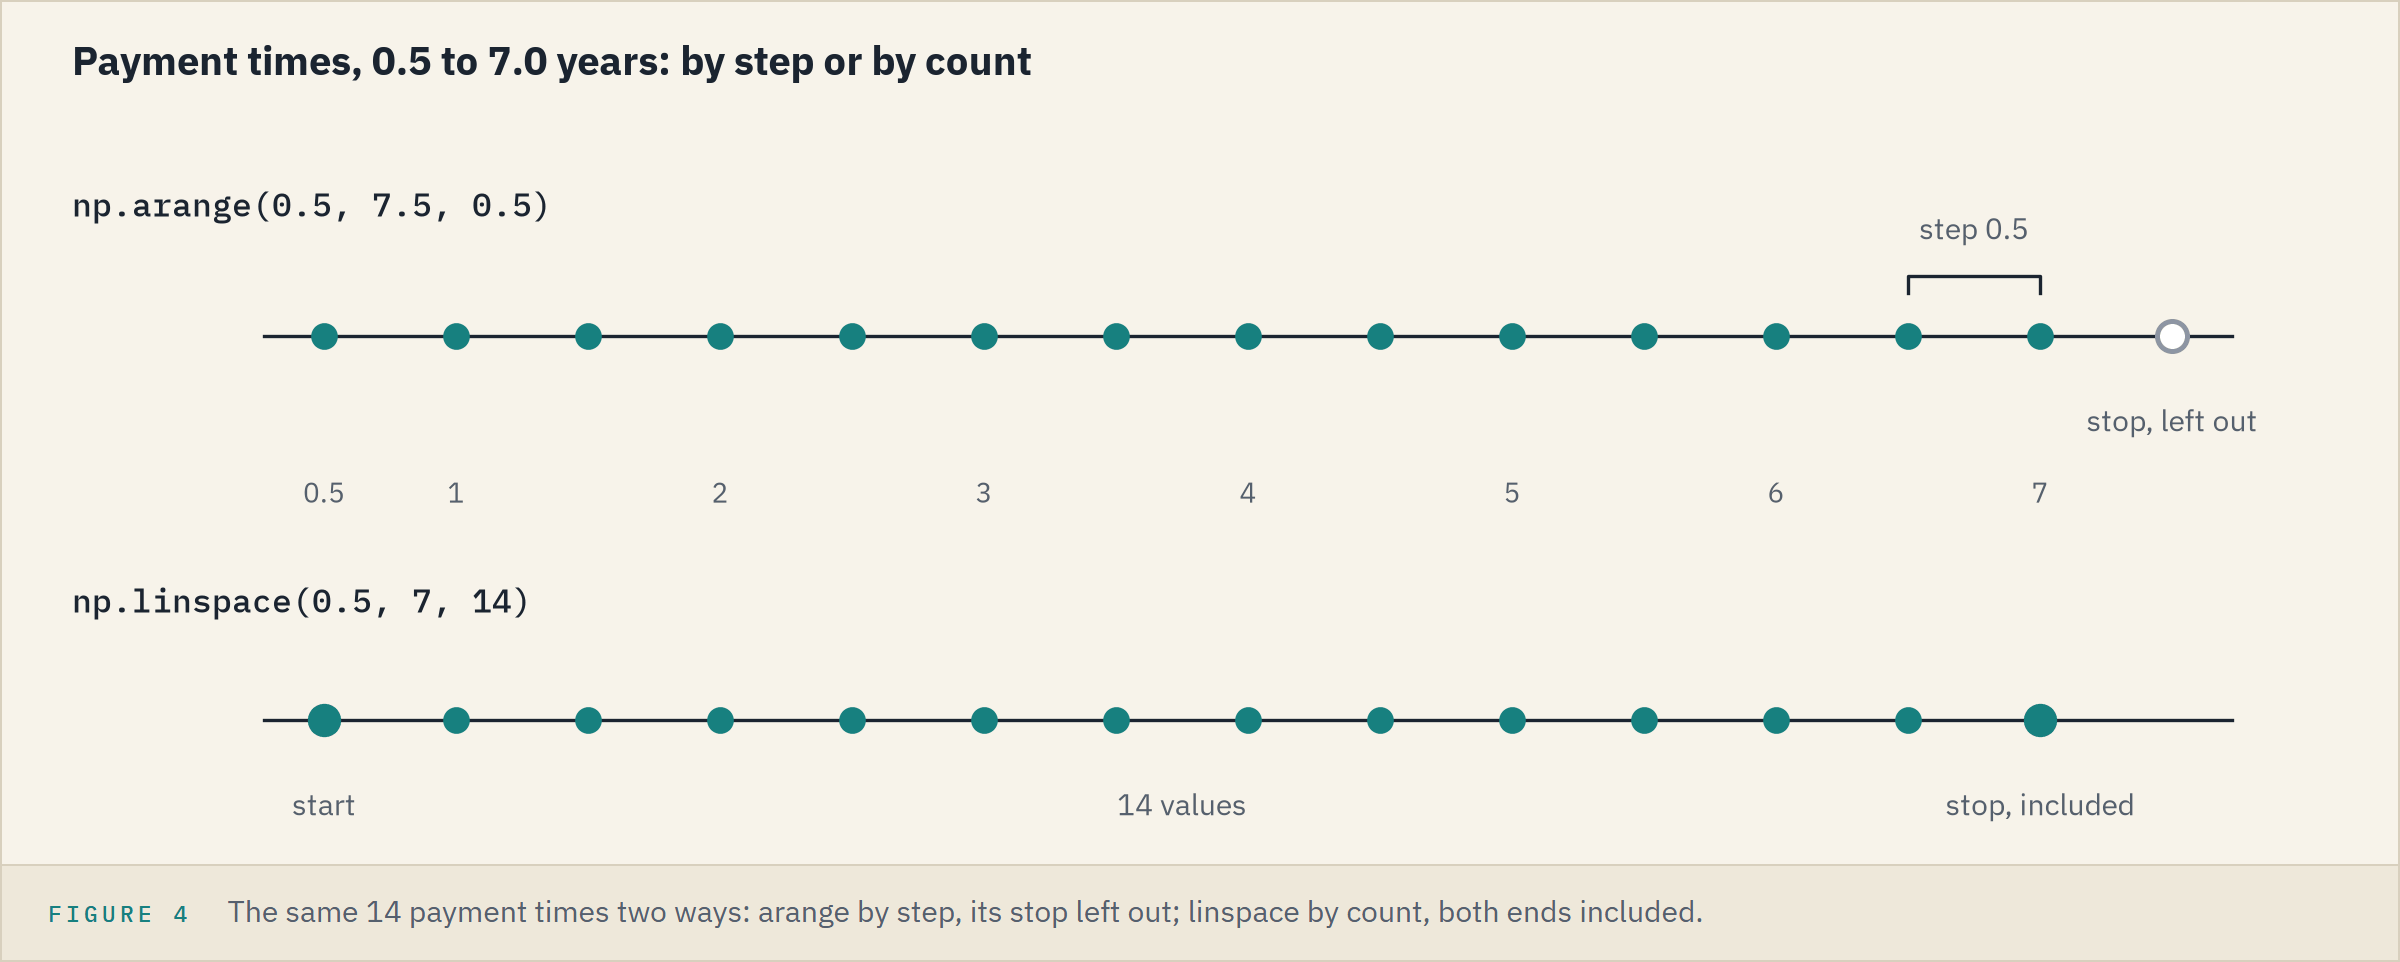

**Excel side by side.** In Microsoft 365 and Excel 2021, `=SEQUENCE(11, 1, 95, 1)` spills the 11 prices: 11 rows, 1 column, from 95, a step of 1.

**Step known: `np.arange()`. Count known: `np.linspace()`.**

### A Step of 0.1

**Predict 2**

Q. The next cell counts from 1 up to 1.3, a step of 0.1, the stop left out. What is the last number?

A) 1.2
B) 1.3

In [10]:
# 1.3 is the stop, so it should be left out
print(np.arange(1, 1.3, 0.1))

[1.  1.1 1.2 1.3]


B: 0.1 is not stored exactly (Day 3), so the count of steps came out a hair above 3, and NumPy added a value.
A step of 0.5 is exact, so the payment times are safe.

**For a decimal step, give `np.linspace()` the count.**

### Zeros and Ones

Q. Make four zeros, a placeholder column for accrued interest, and four redemption values of 100.

In [11]:
# np.zeros(n): n zeros, a placeholder
accrued = np.zeros(4)
print(accrued)
# np.ones(n): n ones; times 100, a constant column
redemptions = np.ones(4) * 100
print(redemptions)

[0. 0. 0. 0.]
[100. 100. 100. 100.]


**We can build arrays. Now calculate with them.**

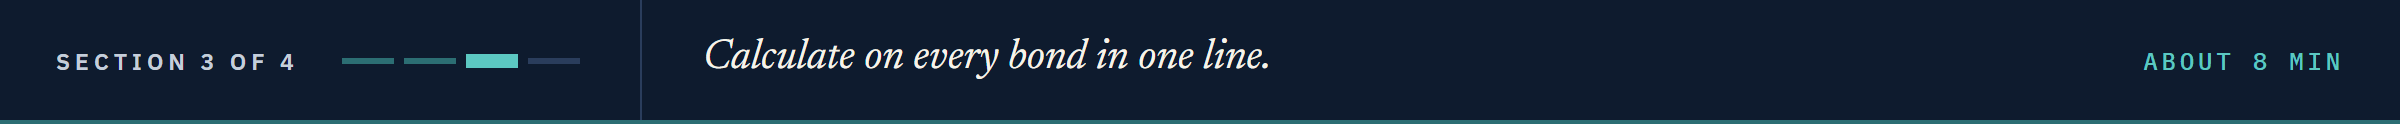

## 6.3 Arithmetic on Whole Arrays

### One Number Across Every Bond

One line that works on every value, like 6.1's cost line, is **vectorized**: NumPy runs the loop itself, inside the library.

Q. Every price rises half a point. What are the new prices?

In [12]:
# one number, added to every value
print(prices + 0.5)
# prices itself is unchanged
print(prices)

[ 99.   103.75  95.5  101.5 ]
[ 98.5  103.25  95.   101.  ]


The result is a new array: store it under a name to keep it.

**A single number reaches every value.**

### Income and Current Yield

Q. What does each position pay a year, and what is each bond's current yield?

In [13]:
# the coupon is in percent, so divide by 100
incomes = faces * coupons / 100
print(incomes)
# coupon over price, in percent; np.round(array, 2) rounds a half to even, as round() does
current_yields = coupons / prices * 100
print(current_yields)
print(np.round(current_yields, 2))

[78750. 30625. 35625. 18750.]
[5.32994924 5.93220339 5.         7.42574257]
[5.33 5.93 5.   7.43]


PLWK is exactly 5: 4.75 over 95 is 0.05.
Round for display only; the full values feed the next calculation.

**Now add them up.**

### The Book's Totals

Q. What did the book cost, and what does it pay a year?

In [14]:
# sum() is a method of the array, called with a dot (Day 4)
print('Total cost:', costs.sum())
print('Annual income:', incomes.sum())

Total cost: 2958750.0
Annual income: 163750.0


**Excel side by side.** Face in B, price in C, coupon in D, costs in E:

<table align="left">
<tr><th align="left">Question</th><th align="left">Python</th><th align="left">Excel</th></tr>
<tr><td align="left">Cost of every position</td><td align="left"><code>faces * prices / 100</code></td><td align="left"><code>=B2*C2/100</code> filled down</td></tr>
<tr><td align="left">Current yield of every bond</td><td align="left"><code>coupons / prices * 100</code></td><td align="left"><code>=D2/C2*100</code> filled down</td></tr>
<tr><td align="left">Total cost</td><td align="left"><code>costs.sum()</code></td><td align="left"><code>=SUM(E2:E5)</code></td></tr>
<tr><td align="left">Total cost in one step</td><td align="left"><code>(faces * prices / 100).sum()</code></td><td align="left"><code>=SUMPRODUCT(B2:B5, C2:C5)/100</code></td></tr>
</table>
<br clear="left">

**2,958,750 and 163,750: Day 4's tied totals, with no loop.**

### Same Yields, Other Order

Q. A colleague multiplies the coupon by 100 before dividing by the price. Do the yields match?

In [15]:
# the same formula, the two steps in the other order
colleague_yields = coupons * 100 / prices
# == compares two arrays value by value
print(current_yields == colleague_yields)
# HLVF's two yields to 15 decimals; [3] picks by position, as in a list
print(f'{current_yields[3]:.15f}')
print(f'{colleague_yields[3]:.15f}')

[ True  True  True False]
7.425742574257425
7.425742574257426


HLVF differs in the 15th decimal; both are 7.43 percent, and neither is wrong.
`==` demands every stored digit: Day 3's `0.1 + 0.2` again.

Q. Compare them, ignoring the last digit.

In [16]:
# np.isclose(): True where two values agree to within a tiny tolerance
print(np.isclose(current_yields, colleague_yields))
# np.allclose(): one answer for the whole array
print(np.allclose(current_yields, colleague_yields))

[ True  True  True  True]
True


`np.isclose()` is Day 3's `math.isclose()` for arrays: by default, within about 1 part in 100,000.
Whole numbers and text are stored exactly, so `==` suits a count, a face, or a ticker.

**Excel side by side.** A tolerance test does the same: `=ABS(F2-G2)<0.000001` or `=ROUND(F2, 6)=ROUND(G2, 6)`.

**Compare decimals with `np.isclose()`, never `==`.**

### Arrays That Do Not Line Up

Q. The desk adds a fifth price but not its face. Cost the book.

In [17]:
# five prices, but faces still holds four: this cell is meant to fail
new_prices = np.array([98.5, 103.25, 95.0, 101.0, 99.0])
faces * new_prices / 100

ValueError: operands could not be broadcast together with shapes (4,) (5,) 

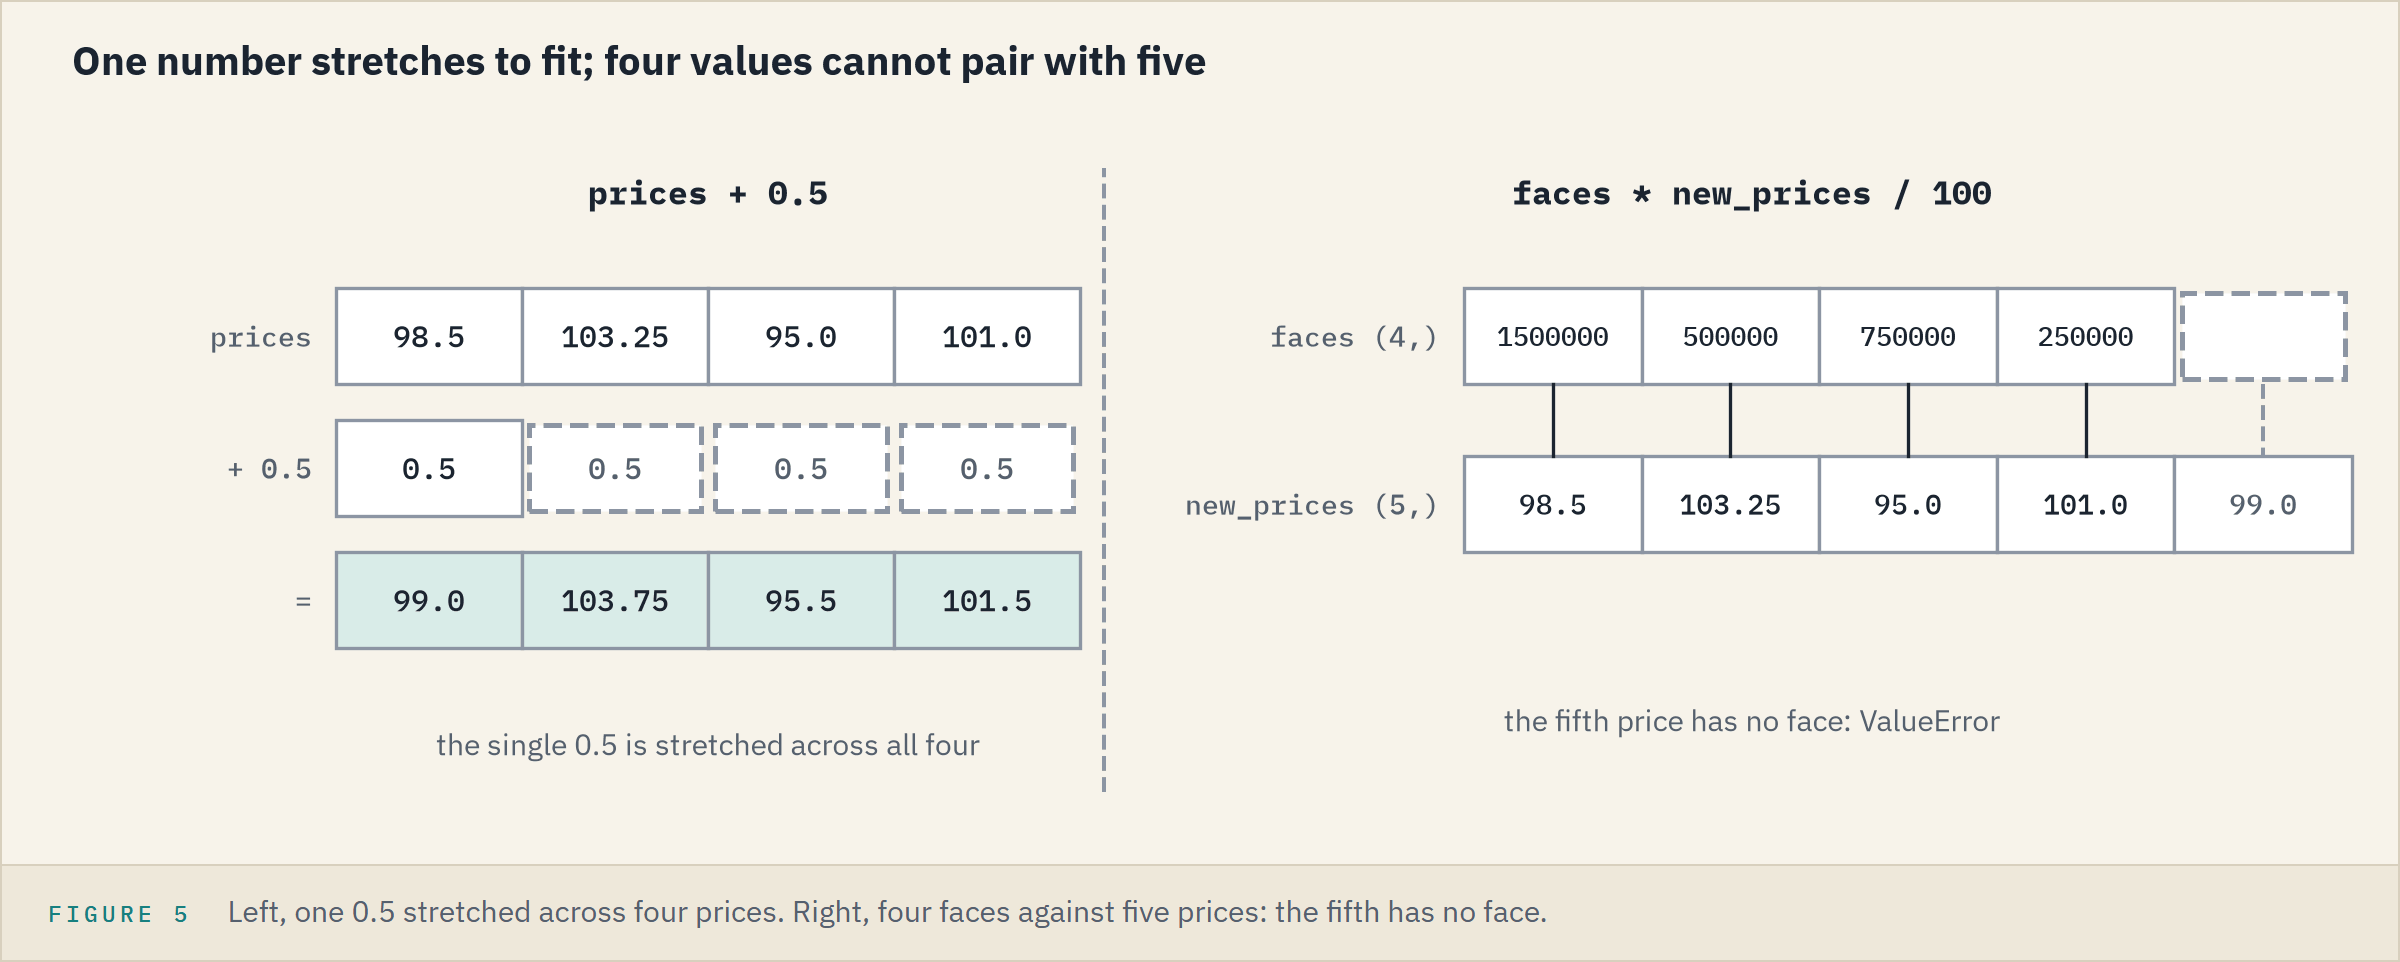

**Broadcast** is NumPy's word for that stretching.
A friendly error: print each array's `shape` to find the culprit.

**Excel side by side.** `=B6*C6/100` filled into a row with no face treats the empty cell as 0, and shows 0.

**NumPy stops when the shapes do not match.**

### A Zero Price

Q. DNMR's price was missing and typed in as 0. What are the current yields?

In [18]:
# DNMR's price typed in as 0
entered_prices = np.array([98.5, 0.0, 95.0, 101.0])
yields_with_zero = coupons / entered_prices * 100
print(yields_with_zero)

[5.32994924        inf 5.         7.42574257]


  yields_with_zero = coupons / entered_prices * 100


A warning, not an error: the cell still ran on to print the yields, with `inf`, infinity, for DNMR.
On Day 3 a zero price stopped the loop with a `ZeroDivisionError`.
Your own run shows a file name before `RuntimeWarning`: the name Jupyter gave the cell.

**Predict 3**

Q. The next cell adds up the four yields. What does it print?

A) An error.
B) About 17.76, the three real yields.
C) `inf`.

In [19]:
# add up the four yields
print(yields_with_zero.sum())

inf


C: no error, and no usable number either.

**Excel side by side.** The zero price shows `#DIV/0!` in the yield, and `=SUM()` over that column returns `#DIV/0!` too.

**An `inf` spreads to every total and average: read warnings.**

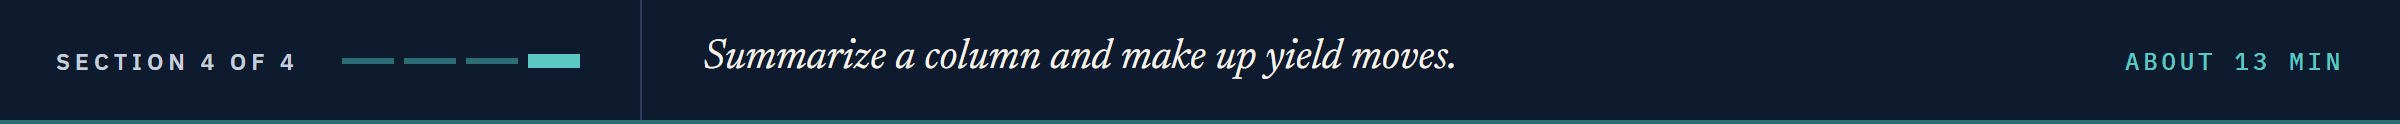

## 6.4 Array Functions

### Sum, Mean, Min, Max, and a Running Total

A summary is a function, `np.sum(costs)`, or a method, `costs.sum()`: the same answer.

Q. What are the total face, the average price and coupon, and the coupon range?

Q. Going down the book, what is the running total of face?

In [20]:
# one NumPy function per summary
print('Total face:', np.sum(faces))
# np.mean(): the simple average, the total over the count
print('Average price:', np.mean(prices))
simple_average = np.mean(coupons)
print('Average coupon:', simple_average)
print('Lowest and highest coupon:', np.min(coupons), np.max(coupons))

Total face: 3000000
Average price: 99.4375
Average coupon: 5.90625
Lowest and highest coupon: 4.75 7.5


In [21]:
# np.cumsum(): the running total
print(np.cumsum(faces))

[1500000 2000000 2750000 3000000]


5.90625 is the simple average week 1's Part 1 printed as 5.906.
4.75 and 7.5 are values: neither says which bond.

**To name the bond, find its position.**

### Which Bond, and in What Order

Q. Which bond has the highest current yield, and which the lowest?

Q. List the coupons lowest first, then the tickers in that order.

In [22]:
# np.argmax(): the position of the largest value, not the value
top = np.argmax(current_yields)
print(top, tickers[top])
# np.argmin(): the same for the smallest
bottom = np.argmin(current_yields)
print(bottom, tickers[bottom])

3 HLVF
2 PLWK


In [23]:
# np.sort(): a sorted copy, with the tickers lost
print(np.sort(coupons))
# np.argsort(): the positions that would sort the array
order = np.argsort(coupons)
print(order)
# positions in the brackets, an array or a list, pick those items, in that order
print(tickers[order])

[4.75  5.25  6.125 7.5  ]
[2 0 1 3]
['PLWK' 'QVNE' 'DNMR' 'HLVF']


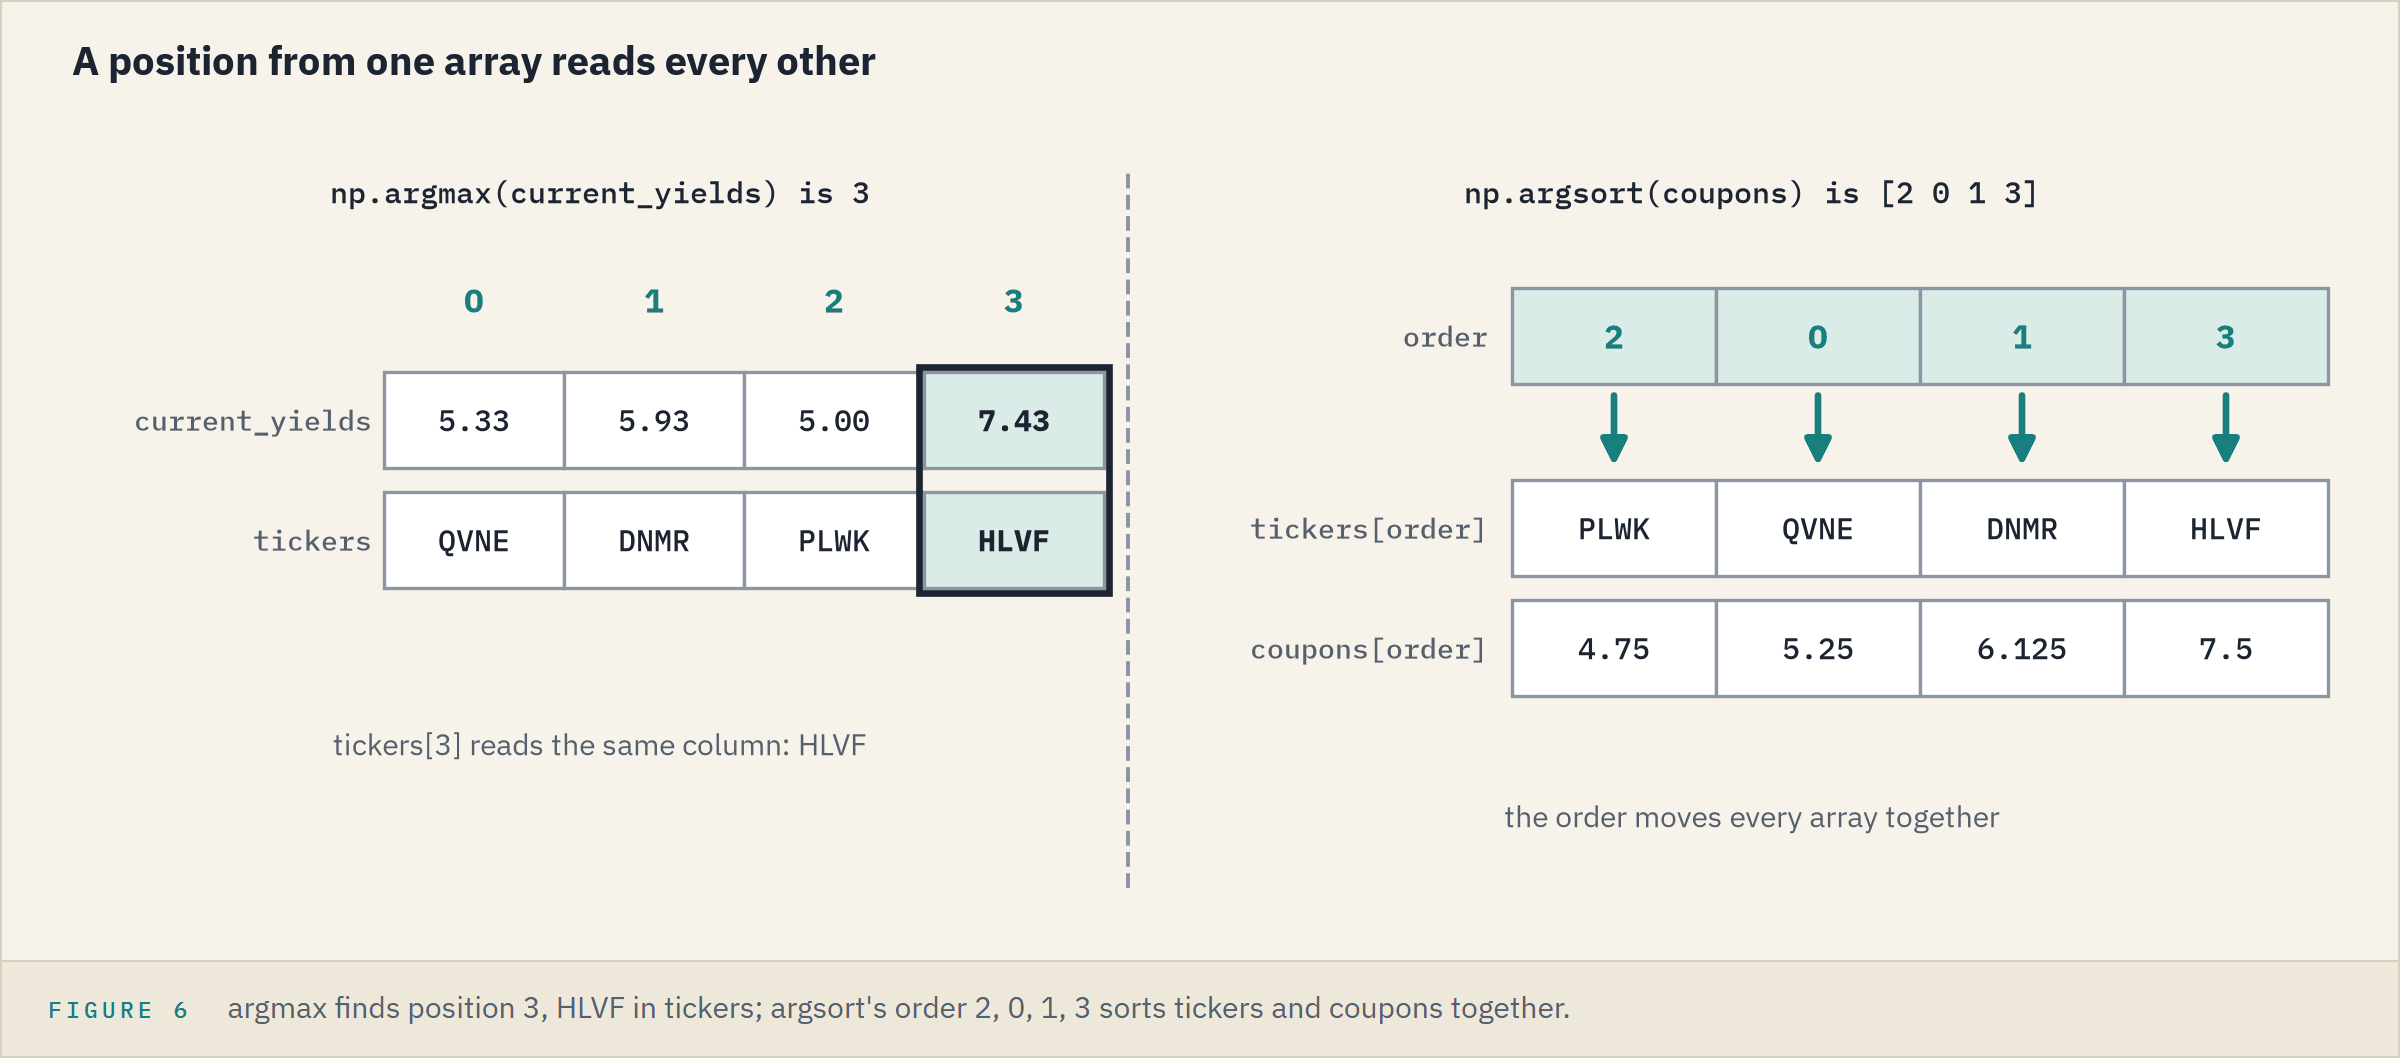

`np.argsort()` is to `np.sort()` what `np.argmax()` is to `np.max()`.
Sorting a table by one column in Excel does the same: every column moves with it.

**Positions keep each bond together. Now the average the note asked for.**

### The Average That Matches the Cash

Week 1's Part 1 promised a weighted average, where bigger positions count more.
The simple 5.90625 counts HLVF's 250,000 like QVNE's 1,500,000.

**Predict 4**

Q. Weight each coupon by its face. Is the weighted average above 5.90625, the same, or below?

A) Above.
B) The same.
C) Below.

In [24]:
# np.average() with the keyword weights= (week 1's Part 2): each coupon counts by its face
weighted_average = np.average(coupons, weights=faces)
print(weighted_average)

5.458333333333333


C, about 5.458: QVNE, the largest position, has a low coupon; HLVF, the highest coupon, is the smallest.

Q. Check it the long way, and against the income.

In [25]:
# each coupon times its face, added up, over the total face
print((coupons * faces).sum() / faces.sum())
# the totals we already have: income over face, in percent
print(incomes.sum() / faces.sum() * 100)

5.458333333333333
5.458333333333333


163,750 a year on 3,000,000 of face is 5.458 percent; 5.90625 matches no cash the book receives.

Q. Draw the coupons and the two averages.

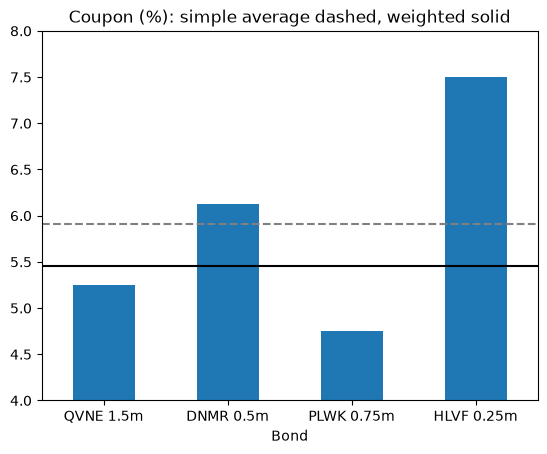

In [26]:
# pandas, imported as in Day 0; each bar labelled with the face held
import pandas as pd
table = pd.DataFrame({'Bond': ['QVNE 1.5m', 'DNMR 0.5m', 'PLWK 0.75m', 'HLVF 0.25m'],
                      'Coupon': coupons})
# ylim= starts the axis at 4, as on Day 5, so the gap between the averages shows
chart = table.plot.bar(x='Bond', y='Coupon', rot=0, legend=False, ylim=(4, 8),
                       title='Coupon (%): simple average dashed, weighted solid')
# axhline(): a line across at one height; linestyle='--' dashes it; named, as chart is
simple_line = chart.axhline(simple_average, color='grey', linestyle='--')
weighted_line = chart.axhline(weighted_average, color='black')

**Excel side by side.** Coupons in D2:D5, face in B2:B5:

<table align="left">
<tr><th align="left">Python</th><th align="left">Excel</th></tr>
<tr><td align="left"><code>np.sum(faces)</code></td><td align="left"><code>=SUM(B2:B5)</code></td></tr>
<tr><td align="left"><code>np.mean(coupons)</code></td><td align="left"><code>=AVERAGE(D2:D5)</code></td></tr>
<tr><td align="left"><code>np.min(coupons)</code></td><td align="left"><code>=MIN(D2:D5)</code></td></tr>
<tr><td align="left"><code>np.max(coupons)</code></td><td align="left"><code>=MAX(D2:D5)</code></td></tr>
<tr><td align="left"><code>tickers[np.argmax(coupons)]</code></td><td align="left"><code>=INDEX(A2:A5, MATCH(MAX(D2:D5), D2:D5, 0))</code></td></tr>
<tr><td align="left"><code>np.round(current_yields, 2)</code></td><td align="left"><code>=ROUND(F2, 2)</code> filled down; a half rounds away from zero there</td></tr>
<tr><td align="left"><code>np.sort(coupons)</code></td><td align="left"><code>=SORT(D2:D5)</code> (Excel 2021, Microsoft 365)</td></tr>
<tr><td align="left"><code>tickers[np.argsort(coupons)]</code></td><td align="left"><code>=SORTBY(A2:A5, D2:D5)</code> (Excel 2021, Microsoft 365)</td></tr>
<tr><td align="left"><code>np.cumsum(faces)</code></td><td align="left"><code>=B2</code> in H2, then <code>=H2+B3</code> filled down</td></tr>
<tr><td align="left"><code>np.average(coupons, weights=faces)</code></td><td align="left"><code>=SUMPRODUCT(D2:D5, B2:B5)/SUM(B2:B5)</code></td></tr>
</table>
<br clear="left">

**5.458 percent is what the book earns.**

### How Spread Out

The **standard deviation**, `std` in Day 5's `describe()`, measures spread: roughly, how far a typical value sits from the average.

Q. What is the standard deviation of the four prices?

Q. Work it by hand, to see why there are two.

In [27]:
# np.std(): the four prices as the whole population
print(np.std(prices))
# ddof=1: the four as a sample of something bigger
print(np.std(prices, ddof=1))

3.063775244694036
3.5377429245212264


In [28]:
# each price's gap from the average, squared so no gap cancels another
squares = (prices - np.mean(prices)) ** 2
print(squares)
# divide by the count, 4, or by one less, 3; np.sqrt() takes the square root
print(np.sqrt(squares.sum() / 4))
print(np.sqrt(squares.sum() / 3))

[ 0.87890625 14.53515625 19.69140625  2.44140625]
3.063775244694036
3.5377429245212264


Only the last division differs: `ddof`, delta degrees of freedom, is the number taken off the count.
Day 5's `describe()` gave the sample one; `np.std()` gives the population one unless told `ddof=1`.

**Excel side by side.** `=STDEV.P(C2:C5)` divides by 4, `=STDEV.S(C2:C5)` by 3.

**When two tools disagree on a standard deviation, check `ddof` first.**

### A Year of Made-Up Yield Moves

Q. Make up 250 days of yield changes in bp to test code on: about 0 on average, about 5 on a typical day.

Q. Draw the 250 changes.

In [29]:
# a random number generator; 42 is the seed: the same seed, the same numbers every run
rng = np.random.default_rng(42)
# 250 draws from a bell curve with average 0 and standard deviation 1, stretched by 5
daily_changes_bp = rng.standard_normal(250) * 5
# [:5] leaves out the start: from the beginning, stopping before 5
print(np.round(daily_changes_bp[:5], 2))
print(round(daily_changes_bp.mean(), 2), round(daily_changes_bp.std(), 2))

[ 1.52 -5.2   3.75  4.7  -9.76]
-0.24 4.69


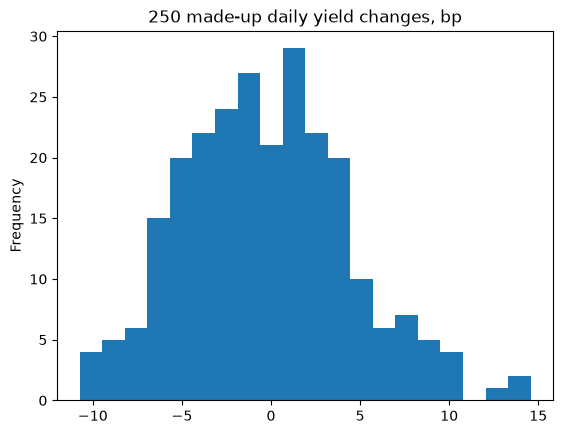

In [30]:
# plot.hist() counts the days that fall in each of 20 equal-width bins
moves = pd.DataFrame({'Change (bp)': daily_changes_bp})
chart = moves.plot.hist(bins=20, legend=False, title='250 made-up daily yield changes, bp')

Near 0 and 5, not exact: a sample lands near its curve, not on it.
A new seed gives new numbers; no seed, new numbers every run.

Q. Draw three numbers between 0 and 1, and six investment grade scores from 1 to 10.

In [31]:
# random(3): 3 numbers from 0 up to, not including, 1
print(np.round(rng.random(3), 3))
# integers(low, high, size=): whole numbers, the high end left out
print(rng.integers(1, 11, size=6))

[0.594 0.146 0.825]
[ 4  4 10  2 10 10]


The 11 makes 10 possible, as the stop does in `np.arange()`.
Older code writes `np.random.rand()`, `randn()`, and `randint()`; `default_rng` is the current way.

**Excel side by side.** `=RAND()`, `=RANDBETWEEN(1, 10)`, and `=NORM.S.INV(RAND())*5` filled down make the same kinds of draws, but recalculate with every change and take no seed.

**Same seed, same numbers: a result that can be rerun.**

### QVNE's Week

Q. QVNE closed at 98.50, 98.70, 98.40, 98.90, and 99.10, Monday to Friday. Draw the week; find each day's change and simple return.

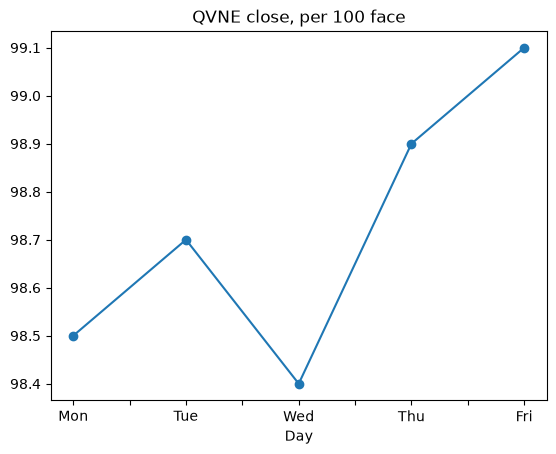

In [32]:
# QVNE's five closes, Monday to Friday
qvne_week = np.array([98.5, 98.7, 98.4, 98.9, 99.1])
# plot.line() joins the closes; marker='o' puts a dot on each
week = pd.DataFrame({'Day': ['Mon', 'Tue', 'Wed', 'Thu', 'Fri'], 'Close': qvne_week})
chart = week.plot.line(x='Day', y='Close', marker='o', legend=False,
                       title='QVNE close, per 100 face')

In [33]:
# np.diff(): each value minus the one before, so one fewer value
price_changes = np.diff(qvne_week)
print(np.round(price_changes, 2))
# [:-1] is every close but the last: yesterday's close for each change
simple_returns = price_changes / qvne_week[:-1]
print(np.round(simple_returns * 100, 4))

[ 0.2 -0.3  0.5  0.2]
[ 0.203  -0.304   0.5081  0.2022]


**Excel side by side.** Closes in B2:B6: the change is `=B3-B2` and the simple return `=B3/B2-1`, filled down.

The **log return** is the natural log of today's close over yesterday's: the power to which e, about 2.718, is raised to give that ratio.
NumPy writes it `np.log()`; Excel, `=LN(B3/B2)`.

Q. What was each day's log return?

In [34]:
# [1:] is every close but the first: today's, over [:-1], yesterday's
log_returns = np.log(qvne_week[1:] / qvne_week[:-1])
print(np.round(log_returns * 100, 4))

[ 0.2028 -0.3044  0.5068  0.202 ]


Each log return sits a little below the simple one; for small moves the two are close.

Q. What did the week return, and do the days add up to it?

In [35]:
# the whole week: the last close over the first
week_ratio = qvne_week[-1] / qvne_week[0]
print('Simple:', round(week_ratio - 1, 6), 'sum of days:', round(simple_returns.sum(), 6))
print('Log:', round(np.log(week_ratio), 6), 'sum of days:', round(log_returns.sum(), 6))
# np.exp() raises e to a power, so it undoes np.log()
print('Undo the log:', round(np.exp(log_returns.sum()) - 1, 6))

Simple: 0.006091 sum of days: 0.006094
Log: 0.006073 sum of days: 0.006073
Undo the log: 0.006091


Daily price ratios multiply, and a log turns multiplying into adding.
`np.exp()`, Excel's `=EXP()`, undoes the log: back to the week's simple return.

**Log returns add up across days; simple returns do not.**

## You Can Now

By the end of this notebook, you can:

* Work out cost, income, and current yield for every bond in one line.
* Say why `*` repeats a list and multiplies an array.
* Build arrays with `np.arange()`, `np.linspace()`, `np.zeros()`, and `np.ones()`.
* Summarize a book: totals, the top bond by name, a face-weighted average.
* Compare decimals with `np.isclose()`, never `==`.
* Read a divide-by-zero warning, and see why one `inf` spoils a total.
* Use a standard deviation, seeded random numbers, and simple and log returns.

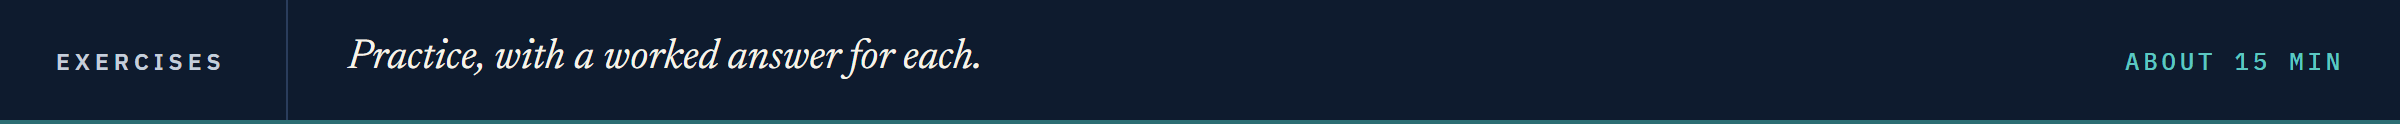

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

A second desk holds three different bonds; the issuers are invented.

<table align="left">
<tr><th align="left">Ticker</th><th align="left">Coupon (%)</th><th align="left">Price</th><th align="left">Rating</th><th align="left">Score</th><th align="left">Face held</th></tr>
<tr><td align="left">TRNW</td><td align="left">4.375</td><td align="left">96.25</td><td align="left">A</td><td align="left">6</td><td align="left">2,000,000</td></tr>
<tr><td align="left">OSMC</td><td align="left">5.00</td><td align="left">100.00</td><td align="left">BBB-</td><td align="left">10</td><td align="left">1,250,000</td></tr>
<tr><td align="left">CLDB</td><td align="left">8.25</td><td align="left">104.50</td><td align="left">B</td><td align="left">15</td><td align="left">500,000</td></tr>
</table>
<br clear="left">

Replace each `...` with your own code, then run the check cell under it.
Run the next cell first: it defines `check`, which marks your answers, allowing tiny rounding differences.

In [36]:
import numpy as np


def check(label, answer, expected):
    """Compare an exercise answer to the expected value and print the result."""
    if answer is ... or answer is None:
        print(label + ': not attempted yet')
        return
    # isinstance(x, np.ndarray) is True when x is a NumPy array;
    # its .dtype.kind is 'f' when it holds decimals
    if isinstance(expected, np.ndarray) and expected.dtype.kind == 'f':
        # arrays of numbers: same shape, and every value within a small tolerance;
        # np.shape() gives the shape of a list too
        correct = np.shape(answer) == expected.shape and np.allclose(answer, expected)
    elif isinstance(expected, np.ndarray):
        # arrays of text: np.array_equal() is True for the same shape and the same values
        correct = np.array_equal(answer, expected)
    elif isinstance(expected, float):
        # single numbers with a decimal point: within a small tolerance;
        # abs() drops the sign, so this is the size of the gap between the two
        correct = abs(answer - expected) < 0.000001
    else:
        correct = answer == expected
    if correct:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have', answer)

### Exercise 1

Q. Create an array for the tickers, coupons, prices, and face held of the three bonds. Then work out the cost of every position in one line, and the total cost. Store the answers in **ex1_costs** and **ex1_total_cost**.

In [37]:
tickers = ...
coupons = ...
prices = ...
faces = ...

ex1_costs = ...
ex1_total_cost = ...

In [38]:
check('Exercise 1 costs', ex1_costs, np.array([1925000.0, 1250000.0, 522500.0]))
check('Exercise 1 total cost', ex1_total_cost, 3697500.0)

Exercise 1 costs: not attempted yet
Exercise 1 total cost: not attempted yet


### Exercise 2

Q. Work out the current yield of every bond, rounded to two decimal places. Find the ticker of the bond with the highest current yield using `np.argmax()`. Then find the face-weighted average coupon. Store the answers in **ex2_current_yields**, **ex2_highest_ticker**, and **ex2_weighted_coupon**.

In [39]:
ex2_current_yields = ...
ex2_highest_ticker = ...
ex2_weighted_coupon = ...

In [40]:
check('Exercise 2 current yields', ex2_current_yields, np.array([4.55, 5.0, 7.89]))
check('Exercise 2 highest ticker', ex2_highest_ticker, 'CLDB')
check('Exercise 2 weighted coupon', ex2_weighted_coupon, 5.1)

Exercise 2 current yields: not attempted yet
Exercise 2 highest ticker: not attempted yet
Exercise 2 weighted coupon: not attempted yet


### Exercise 3

A calculation needed again belongs in a function: next month it runs on the new holdings.

Q. Write a function `annual_income(faces, coupons)` that takes an array of face amounts and an array of annual coupons in percent, and returns the total annual coupon income as one number. The first line and the docstring are given. Replace the `...` in the body with your code, and end it with `return`.

Q. The income divided by the total face, times 100, is the face-weighted average coupon. Call your function on the three bonds, and use `np.isclose()` to test whether that figure agrees with **ex2_weighted_coupon**. Store the True or False in **ex3_agrees**.

In [41]:
def annual_income(faces, coupons):
    """
    Take an array of face amounts and an array of annual coupons in percent,
    and return the total annual coupon income as a single number.
    """
    ...


ex3_agrees = ...

In [42]:
# the check calls your function on the three bonds
check('Exercise 3 income', annual_income(np.array([2000000, 1250000, 500000]),
                                         np.array([4.375, 5.0, 8.25])), 191250.0)
check('Exercise 3 agrees', ex3_agrees, True)

Exercise 3 income: not attempted yet
Exercise 3 agrees: not attempted yet


### Exercise 4

CLDB closed at 104.50, 104.00, 104.25, and 105.00 on four days.

Q. Put the four closes in an array. Find the simple return on each of the three days, as a decimal, and store the three returns in **ex4_simple_returns**. Find the sum of the daily log returns and store it in **ex4_log_total**. Then find the sample standard deviation of the four closes and store it in **ex4_sample_std**.

In [43]:
ex4_simple_returns = ...
ex4_log_total = ...
ex4_sample_std = ...

In [44]:
check('Exercise 4 simple returns', ex4_simple_returns,
      np.array([-0.00478469, 0.00240385, 0.00719424]))
check('Exercise 4 log total', ex4_log_total, 0.00477328)
check('Exercise 4 sample standard deviation', ex4_sample_std, 0.42695628)

Exercise 4 simple returns: not attempted yet
Exercise 4 log total: not attempted yet
Exercise 4 sample standard deviation: not attempted yet


### Exercise 5: AI check

You ask an AI assistant for code that gives the weighted average coupon of the three positions; it has one bug.

Q. Read the code before you run it: you worked out the face-weighted average coupon in Exercise 2. Then run it. Does it agree with you?

Q. Find the bug and fix the code below, so that **ex5_weighted_coupon** holds the right answer.

In [45]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
ai_coupons = np.array([4.375, 5.0, 8.25])
ai_prices = np.array([96.25, 100.0, 104.5])
ai_faces = np.array([2000000, 1250000, 500000])

# weight each coupon by its position in the portfolio
ex5_weighted_coupon = np.average(ai_coupons, weights=ai_prices)
print(f'The weighted average coupon is {round(ex5_weighted_coupon, 2)} percent')

The weighted average coupon is 5.93 percent


In [46]:
check('Exercise 5', ex5_weighted_coupon, 5.1)

Exercise 5: not yet. You have 5.929239401496259


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">Cost and income</td><td align="left">2,958,750 and 163,750 a year, one line each</td></tr>
<tr><td align="left">Current yields</td><td align="left"><code>coupons / prices * 100</code>: 5.00 to 7.43 percent</td></tr>
<tr><td align="left">The top yielder</td><td align="left">HLVF, by <code>np.argmax()</code></td></tr>
<tr><td align="left">The average that matches the cash</td><td align="left">5.458 percent, face-weighted</td></tr>
<tr><td align="left">A year of test moves</td><td align="left">250 seeded draws, the same on every run</td></tr>
<tr><td align="left">QVNE's week</td><td align="left">0.609 percent; the daily log returns add up to its log</td></tr>
</table>
<br clear="left">

A list could not multiply face by price; now one line prices the whole book.
Be proud: this is a desk's everyday arithmetic, and you wrote every line.

In NumPy, Part 2, you pick bonds out of an array by a condition, price a bond from its cash flows, and hold the whole book in one array, all with no loop.

[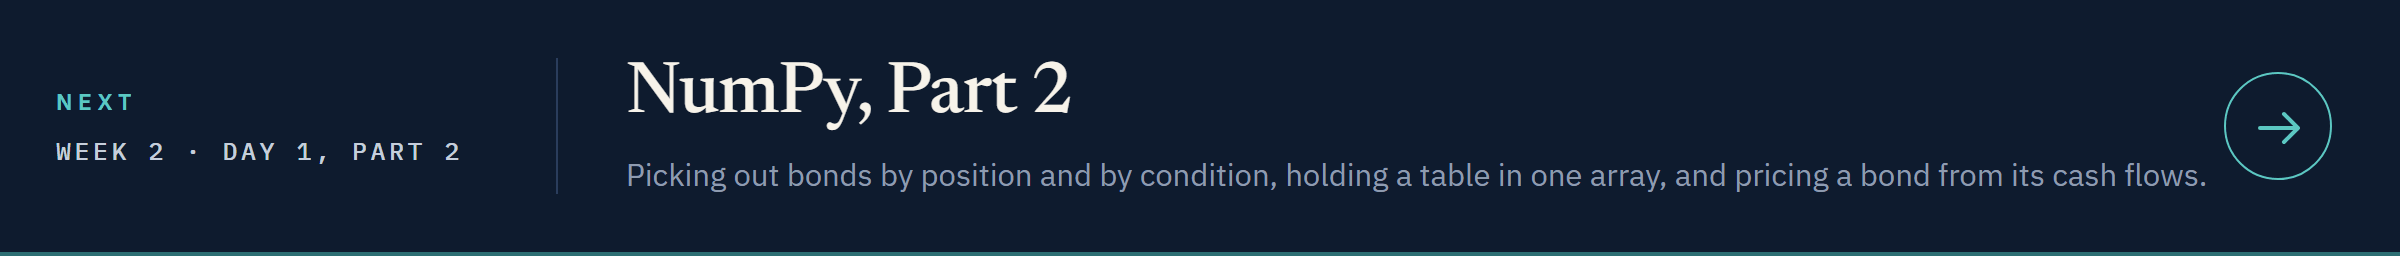](../day1_part2/06_part2_numpy.ipynb)

[Open Day 1, Part 2 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week2/day1_part2/06_part2_numpy.ipynb)